In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/creditcard.csv")
print(df.shape)
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True) * 100)

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [3]:
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")
df.info()

0 missing values
1081 duplicate rows
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-nul

In [4]:
print(df.groupby("Class")["Amount"].describe())


          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


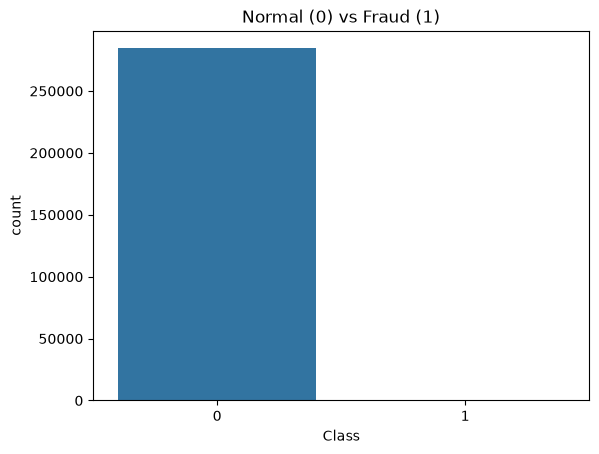

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="Class", data=df)
plt.title("Normal (0) vs Fraud (1)")
plt.show()

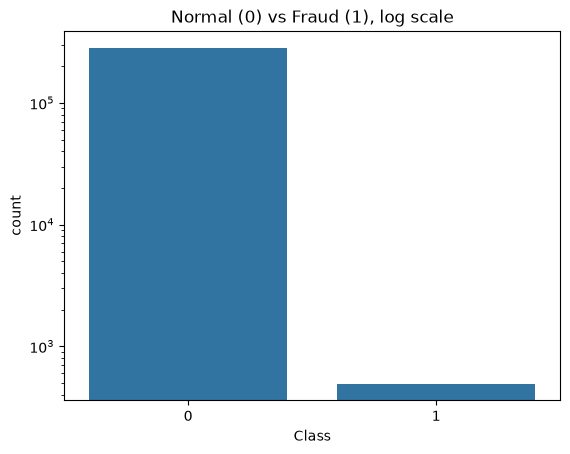

In [6]:
sns.countplot(x="Class", data=df)
plt.yscale("log")
plt.title("Normal (0) vs Fraud (1), log scale")
plt.show()

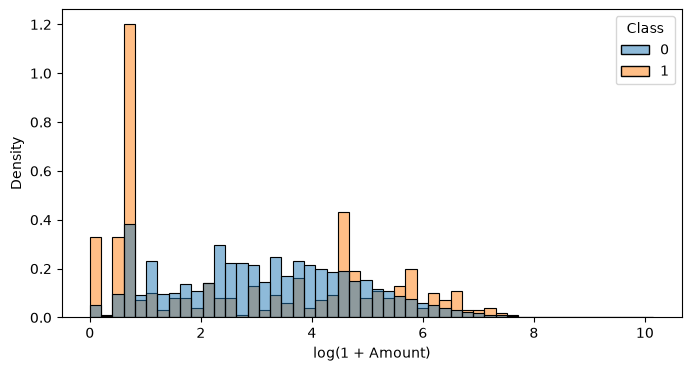

In [7]:
import numpy as np

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x=np.log1p(df["Amount"]), hue="Class",
             stat="density", common_norm=False, bins=50)
plt.xlabel("log(1 + Amount)")
plt.show()

In [ ]:
Frauds (orange) concentrate on very small amounts, with a huge spike at about $1 and another at $0. This is typical card testing: a fraudster makes a tiny purchase to check that a stolen card works before using it for something bigger.
A second fraud spike appears near $100, a round amount. Fraudsters like round numbers.
Normal transactions (blue) are spread smoothly over a wide range, mostly between about $7 and $150 (x from 2 to 5), like everyday purchases.

Lesson: fraud has recognizable amount patterns (tiny or round amounts), but plenty of frauds look like ordinary amounts too. So Amount helps, but it isn’t enough alone.

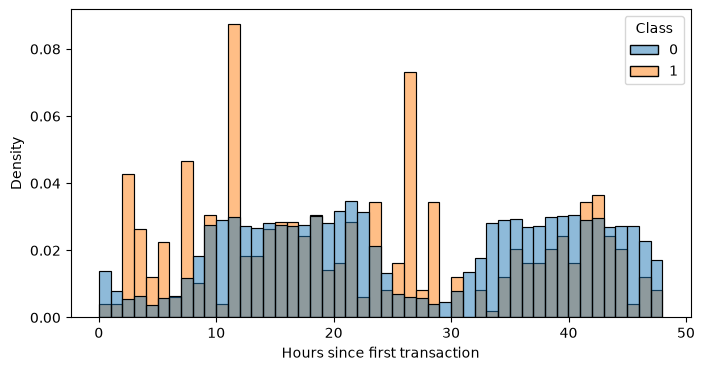

In [8]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x=df["Time"] / 3600, hue="Class",
             stat="density", common_norm=False, bins=48)
plt.xlabel("Hours since first transaction")
plt.show()

In [ ]:
Normal transactions follow a day/night rhythm. They dip around hours 0 to 8 and hours 26 to 32 (the quiet nighttime of each day) and peak during the day.
Frauds don’t follow that rhythm. They’re spread more evenly, with spikes at hours around 2, 7 to 8, 11 and 26 to 28, including during the quiet night hours when few normal transactions happen.

Lesson: at night, a larger share of transactions are fraudulent. A model could use “what time of day is it?” as a signal.

In [10]:
df["Hour"] = (df["Time"] / 3600) % 24

In [11]:
corr = df.corr()["Class"].drop("Class").sort_values()
print(corr)

V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V6       -0.043643
Hour     -0.017082
Time     -0.012323
V24      -0.007221
V13      -0.004570
V15      -0.004223
V23      -0.002685
V22       0.000805
V25       0.003308
V26       0.004455
Amount    0.005632
V28       0.009536
V27       0.017580
V8        0.019875
V20       0.020090
V19       0.034783
V21       0.040413
V2        0.091289
V4        0.133447
V11       0.154876
Name: Class, dtype: float64


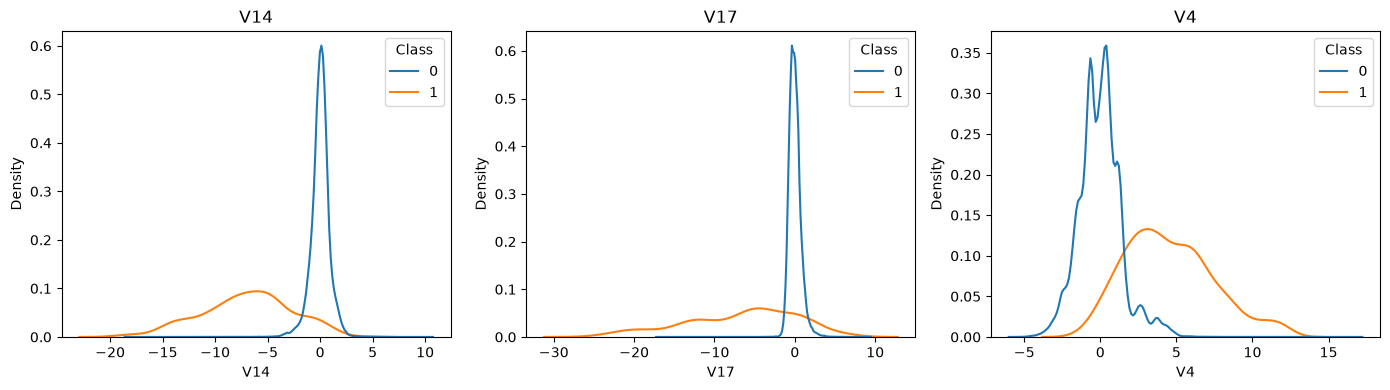

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["V14", "V17", "V4"]):
    sns.kdeplot(data=df, x=col, hue="Class", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [13]:
df.duplicated().sum()

np.int64(1081)

In [14]:
   corr = df.corr()["Class"].drop("Class").sort_values()
   print(corr.head(5))
   print(corr.tail(5))

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
Name: Class, dtype: float64


In [15]:
dups = df[df.duplicated()]
print(dups["Class"].value_counts())

Class
0    1062
1      19
Name: count, dtype: int64


In [16]:
df_clean = df.drop_duplicates()
print(df.shape, "->", df_clean.shape)
print(df_clean["Class"].value_counts())

(284807, 32) -> (283726, 32)
Class
0    283253
1       473
Name: count, dtype: int64


In [17]:
   corr = df.corr()["Class"].drop("Class").sort_values()
   print(corr.head(5))
   print(corr.tail(5))

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
Name: Class, dtype: float64
